# Task 4.4

Test-sweep exception: lambda is fixed by internal validation before the required test-error sweep.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from threadpoolctl import threadpool_limits
from scipy.optimize import minimize
from scipy.special import expit

threadpool_limits(limits=1)
FAST = True


In [2]:
def std(x, m=None, s=None):
    if m is None:
        m = x.mean(axis=0)
        s = x.std(axis=0)
        s = np.where(s < 1e-12, 1, s)
    return (x - m) / s, m, s


def poly(x):
    c = [np.ones(len(x))]
    for i in range(x.shape[1]):
        c.append(x[:, i])
    for i in range(x.shape[1]):
        for j in range(i, x.shape[1]):
            c.append(x[:, i] * x[:, j])
    return np.column_stack(c)


def pnames(nm):
    s = ['bias'] + list(nm)
    for i in range(len(nm)):
        for j in range(i, len(nm)):
            s.append(str(nm[i]) + ' * ' + str(nm[j]))
    return s


def design(tr, te=None):
    x, m0, s0 = std(tr)
    x, m, s = std(poly(x)[:, 1:])
    z = np.column_stack([np.ones(len(x)), x])
    if te is None:
        return z
    x0, _, _ = std(te, m0, s0)
    x0, _, _ = std(poly(x0)[:, 1:], m, s)
    return z, np.column_stack([np.ones(len(x0)), x0])


def soft(w, t):
    return np.sign(w) * np.maximum(np.abs(w) - t, 0)


def loss(w, z, y, l=0):
    s = y * (z @ w)
    p = w.copy()
    p[0] = 0
    e = np.mean(np.logaddexp(0, -s)) + l*(p @ p)
    g = z.T @ (-y * expit(-s)) / len(y) + 2*l*p
    return e, g


def l2(z, y, l, w=None):
    if w is None:
        w = np.zeros(z.shape[1])
    res = minimize(loss, w, args=(z, y, l), method='L-BFGS-B', jac=True,
                   options=dict(gtol=1e-8, ftol=1e-14, maxiter=10000, maxls=50))
    assert res.success or np.max(np.abs(res.jac)) < 1e-5
    return res.x


def l1(z, y, l, w, h):
    p = np.ones(z.shape[1])
    p[0] = 0
    w = w.copy()
    v, t = w.copy(), 1.0
    for i in range(1, 100001):
        a = soft(v - h*loss(v, z, y)[1], h*l*p)
        t1 = (1 + np.sqrt(1 + 4*t*t)) / 2
        v = a + (t - 1)/t1 * (a - w)
        w, t = a, t1
        if i % 25 == 0:
            a = soft(w - h*loss(w, z, y)[1], h*l*p)
            if np.max(np.abs(a - w)) / h < 1e-6:
                return w
    raise RuntimeError('L1 did not converge')


def path(z, y, ls, p):
    ws = np.zeros((len(ls), z.shape[1]))
    w = np.zeros(z.shape[1])
    h = 4*len(y) / np.linalg.norm(z, 2)**2 if p == 'L1' else None
    for j in range(len(ls) - 1, -1, -1):
        if p == 'L1':
            w = l1(z, y, ls[j], w, h)
        else:
            w = l2(z, y, ls[j], w)
        ws[j] = w
    return ws


def split(y, rng):
    tr, va = [], []
    for c in [-1, 1]:
        idx = rng.permutation(np.flatnonzero(y == c))
        n = round(0.2*len(idx))
        va.extend(idx[:n])
        tr.extend(idx[n:])
    return rng.permutation(tr), rng.permutation(va)


def pred(s):
    return np.where(s >= 0, 1, -1)


In [3]:
rng0 = np.random.default_rng(408)
z0 = np.column_stack([np.ones(20), rng0.normal(size=(20, 3))])
y0 = rng0.choice([-1, 1], size=20)
w0 = rng0.normal(size=4)
g0 = loss(w0, z0, y0, 0.2)[1]
g1 = np.zeros(4)
for j in range(4):
    d0 = np.zeros(4)
    d0[j] = 1e-5
    g1[j] = (loss(w0+d0, z0, y0, 0.2)[0] - loss(w0-d0, z0, y0, 0.2)[0]) / 2e-5
assert np.linalg.norm(g0-g1) / (np.linalg.norm(g0)+np.linalg.norm(g1)) < 1e-6
assert np.isfinite(np.logaddexp(0, [-1000, 1000])).all()


In [4]:
from sklearn.datasets import load_breast_cancer

ds = load_breast_cancer()
x = ds.data
y = np.where(ds.target == 0, 1, -1)
rng = np.random.default_rng(407)
idx = rng.permutation(len(y))
tr, te = idx[:100], idx[100:]
tr2, va = split(y[tr], rng)
z1, z2 = design(x[tr[tr2]], x[tr[va]])
ls = np.logspace(-3, 0, 16 if FAST else 25)
nm = pnames(ds.feature_names)[1:]
ev = np.empty((2, len(ls)))
b = []

for p, pen in enumerate(["L1", "L2"]):
    w = path(z1, y[tr[tr2]], ls, pen)
    yp = pred(z2 @ w.T)
    ev[p] = np.mean(yp != y[tr[va], None], axis=0)

    b.append(np.flatnonzero(ev[p] == ev[p].min())[-1])
    print(pen, "validation-selected lambda:", ls[b[-1]], flush=True)

b = np.array(b)


L1 validation-selected lambda: 0.1584893192461114
L2 validation-selected lambda: 1.0


In [5]:
zt, ze = design(x[tr], x[te])
assert zt.shape == (100, 496)
ei = np.empty_like(ev)
et = np.empty_like(ev)
ws = []
for p, pen in enumerate(["L1", "L2"]):
    w = path(zt, y[tr], ls, pen)
    ws.append(w)
    yp1 = pred(zt @ w.T)
    yp2 = pred(ze @ w.T)
    ei[p] = np.mean(yp1 != y[tr, None], axis=0)
    et[p] = np.mean(yp2 != y[te, None], axis=0)
    print(f"{pen}: lambda={ls[b[p]]:.4g}, "
          f"train error={ei[p, b[p]]:.4f}, test error={et[p, b[p]]:.4f}")

ws = np.array(ws)
nz = np.sum(np.abs(ws[0, :, 1:]) > 1e-7, axis=1)


L1: lambda=0.1585, train error=0.0300, test error=0.0789
L2: lambda=1, train error=0.0500, test error=0.1258


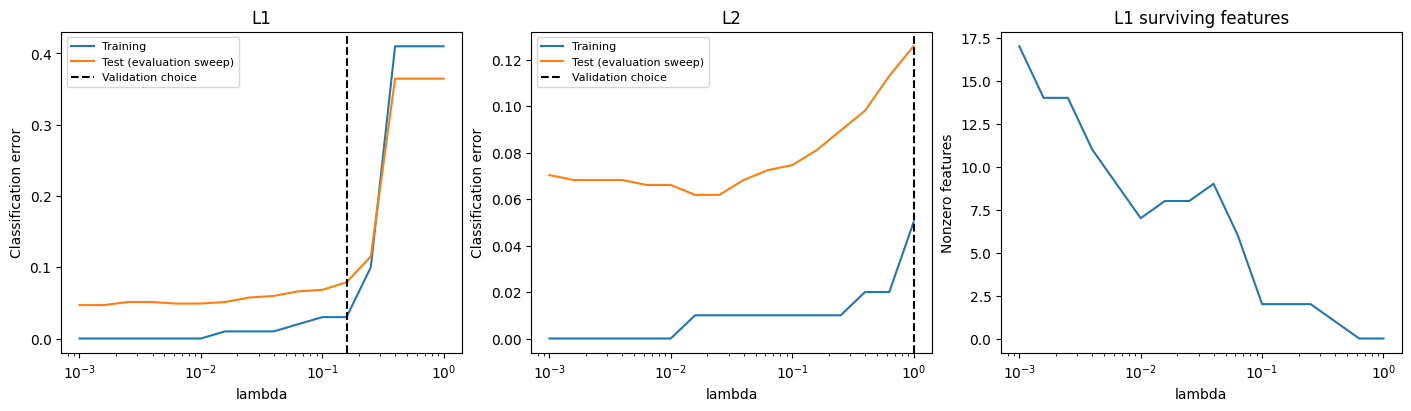

In [6]:
fig, axs = plt.subplots(1, 3, figsize=(14, 4), layout="constrained")
for p, pen in enumerate(["L1", "L2"]):
    axs[p].plot(ls, ei[p], label="Training")
    axs[p].plot(ls, et[p], label="Test (evaluation sweep)")
    axs[p].axvline(ls[b[p]], linestyle="--", color="black", label="Validation choice")
    axs[p].set_xscale("log")
    axs[p].set(xlabel="lambda", ylabel="Classification error", title=pen)
    axs[p].legend(fontsize=8)
axs[2].plot(ls, nz)
axs[2].set_xscale("log")
axs[2].set(xlabel="lambda", ylabel="Nonzero features", title="L1 surviving features")
plt.show()


In [7]:
w0 = ws[0, b[0], 1:]
keep = np.flatnonzero(np.abs(w0) > 1e-7)
print("L1 features at the validation-selected lambda:")
for j in keep:
    print(f"{nm[j]}: {w0[j]:.6f}")


L1 features at the validation-selected lambda:
worst perimeter: 0.373177
worst concave points: 1.008679
